In [ ]:
import pandas as pd
import pickle
import os
import time
import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
#from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

2024-02-08 20:25:52.983079: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-08 20:25:53.021312: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-08 20:25:53.021331: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-08 20:25:53.021349: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-08 20:25:53.028444: I tensorflow/core/platform/cpu_feature_g

In [13]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# ResNet 50

In [16]:
IMG_SHAPE = (img_height, img_width,3)
base_model_ResNet50 = tf.keras.applications.ResNet50(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [17]:
base_model_ResNet50.trainable = False
base_model_ResNet50.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_1[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                       

In [18]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_ResNet50 = base_model_ResNet50(image_batch)
print(feature_batch_ResNet50.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_ResNet50 = global_average_layer(feature_batch_ResNet50)
print(feature_batch_average_ResNet50.shape)
prediction_layer_ResNet50 = tf.keras.layers.Dense(1)
prediction_batch_ResNet50 = prediction_layer_ResNet50(feature_batch_average_ResNet50)
print(prediction_batch_ResNet50.shape)

2024-02-06 21:05:16.304264: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:442] Loaded cuDNN version 8904


(32, 7, 7, 2048)
(32, 2048)
(32, 1)


In [19]:
inputs_ResNet50 = tf.keras.Input(shape=(img_height, img_width,3))
x_ResNet50 = data_augmentation(inputs_ResNet50)
x_ResNet50 = tf.keras.applications.resnet.preprocess_input (x_ResNet50)
x_ResNet50 = base_model_ResNet50(x_ResNet50, training=False) 
x_ResNet50 = global_average_layer(x_ResNet50)
x_ResNet50 = tf.keras.layers.Dropout(0.2)(x_ResNet50)
outputs_ResNet50 = prediction_layer_ResNet50(x_ResNet50)
model_ResNet50 = tf.keras.Model(inputs_ResNet50, outputs_ResNet50)

In [20]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [21]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./ResNet50.h5'

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')

model_ResNet50.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [22]:
model_ResNet50.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem (  (None, 224, 224, 3)       0         
 SlicingOpLambda)                                                
                                                                 
 tf.nn.bias_add (TFOpLambda  (None, 224, 224, 3)       0         
 )                                                               
                                                                 
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (  (None, 2048)              0     

In [23]:
initial_epochs = 5
loss0, accuracy0 = model_ResNet50.evaluate(val_ds)

36/36 [==============================] - 4s 49ms/step - loss: 0.8715 - accuracy: 0.5462


In [24]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 0.8715
initial accuracy: 0.5462


In [25]:
%%time
# Training
history_ResNet50 = model_ResNet50.fit(train_ds, epochs=initial_epochs, validation_data=val_ds,
                                      callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_ResNet50.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5


2024-02-06 21:05:29.909778: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x7eeb70aafc20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-02-06 21:05:29.909797: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2024-02-06 21:05:29.925780: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-02-06 21:05:30.044869: I ./tensorflow/compiler/jit/device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


212/213 [============================>.] - ETA: 0s - loss: 0.3725 - accuracy: 0.8284
Epoch 1: val_loss improved from inf to 0.15167, saving model to ./ResNet50.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 15s 53ms/step - loss: 0.3713 - accuracy: 0.8290 - val_loss: 0.1517 - val_accuracy: 0.9840
Epoch 2/5
213/213 [==============================] - ETA: 0s - loss: 0.1034 - accuracy: 0.9821
Epoch 2: val_loss improved from 0.15167 to 0.08796, saving model to ./ResNet50.h5
213/213 [==============================] - 10s 48ms/step - loss: 0.1034 - accuracy: 0.9821 - val_loss: 0.0880 - val_accuracy: 0.9822
Epoch 3/5
213/213 [==============================] - ETA: 0s - loss: 0.0760 - accuracy: 0.9850
Epoch 3: val_loss improved from 0.08796 to 0.06467, saving model to ./ResNet50.h5
213/213 [==============================] - 10s 49ms/step - loss: 0.0760 - accuracy: 0.9850 - val_loss: 0.0647 - val_accuracy: 0.9849
Epoch 4/5
213/213 [==============================] - ETA: 0s - loss: 0.0641 - accuracy: 0.9860
Epoch 4: val_loss improved from 0.06467 to 0.05933, saving model to ./ResNet50.h5
213/213 [==============================] - 10s 48ms/step - loss: 0.064

In [26]:
acc_ResNet50 = history_ResNet50.history['accuracy']
val_acc_ResNet50 = history_ResNet50.history['val_accuracy']

loss_ResNet50 = history_ResNet50.history['loss']
val_loss_ResNet50 = history_ResNet50.history['val_loss']

## Test_ds (ResNet50)

Predictions:
 [0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1
 0 1 1 1 0 0 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 0
 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 0 0 0 1 0 1 1 1 1 1
 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 0 1 0
 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0
 1 0 1 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1
 0 0 1 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0
 0 1 1 0 0 0 0 0 1 0 0 1 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 1 1 0
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 1 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0
 1 0 0 1 1 

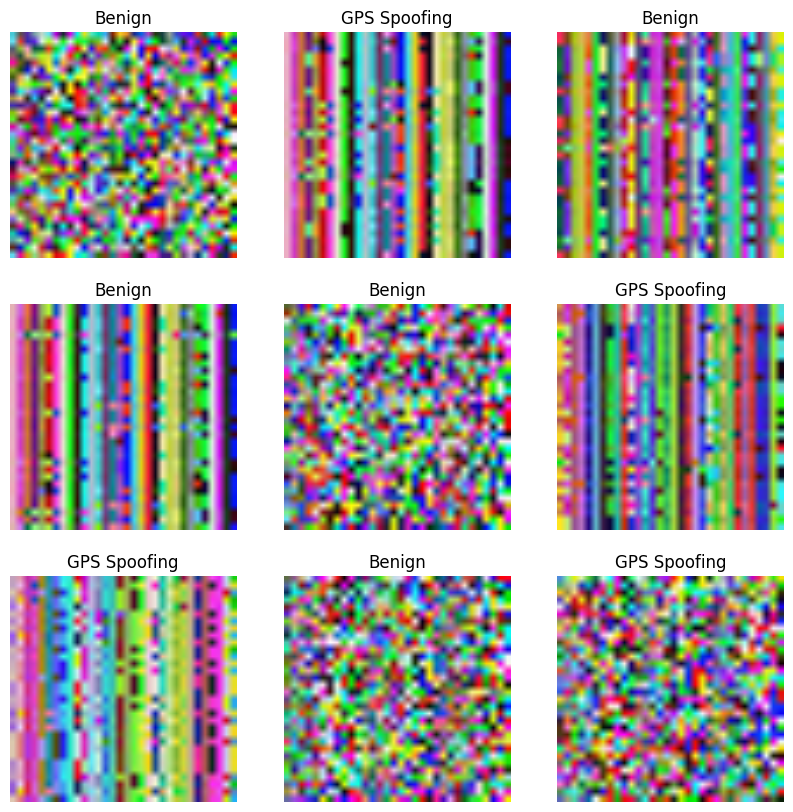

In [27]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet50 = []
all_label_ResNet50 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)
    
all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)

report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

In [28]:
cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
TP = np.sum((all_predictions_ResNet50 == 1) & (all_label_ResNet50 == 1))
FP = np.sum((all_predictions_ResNet50 == 1) & (all_label_ResNet50 == 0))
FN = np.sum((all_predictions_ResNet50 == 0) & (all_label_ResNet50 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_label_ResNet50)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_label_ResNet50 , all_predictions_ResNet50).ravel()
specificity = TN / (TN + FP)

Test_ds (ResNet50)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       332
GPS Spoofing       1.00      0.97      0.98       244

    accuracy                           0.99       576
   macro avg       0.99      0.98      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9861111111111112
                  
2) Precision: 0.9864379084967321
                  
3) Recall: 0.9861111111111112
                  
4) Average F1-score: 0.9860780423280422
                  
5) F1-score for each type of attack: [0.98809524 0.98333333]
                  
6) Average ROC AUC: 0.9836065573770492
                  
7) Average PR AUC: 0.9811020036429873
                  
8) Balanced Accuracy: 0.9836065573770492
                  
9) Hinge: 0.5902777777777778
                  
10) Matthews Correlation Coefficient: 0.9718308284433178
                  
11) Jaccard Score: 0.96721

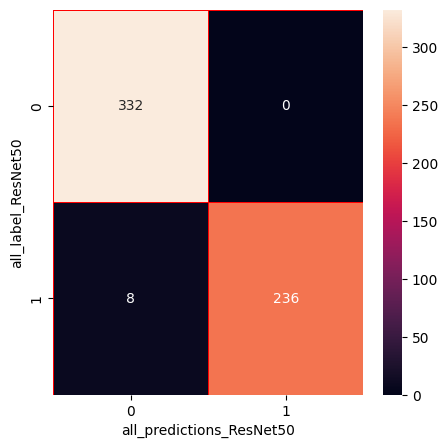

In [29]:
print("Test_ds (ResNet50)")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [30]:
loss_test_ResNet50, accuracy_test_ResNet50 = model_ResNet50.evaluate(test_ds) 
print("Test loss: {:.4f}".format(loss_test_ResNet50))
print("Test accuracy: {:.4f}".format(accuracy_test_ResNet50))

18/18 [==============================] - 1s 36ms/step - loss: 0.0389 - accuracy: 0.9913
Test loss: 0.0389
Test accuracy: 0.9913


In [31]:
saved_info = {
    'class_names': class_names,
    'all_label_ResNet50': all_label_ResNet50,
    'all_predictions_ResNet50': all_predictions_ResNet50,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'precision_score': precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'recall_score': recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_weighted': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_each': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Hinge': hinge_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50),
    'Jaccard Score': jaccard_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Log Loss': log_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Zero-One Loss': zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet50_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [32]:
with open('ResNet50_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label_ResNet50'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet50'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1
 0 1 1 1 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 0
 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1
 1 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 0 1 0
 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0
 1 0 1 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1
 0 0 1 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0
 0 1 1 0 0 0 0 0 1 0 0 1 1 1 1 0 0 1 1 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 1 1 0
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1
 0 1 1 1 0 1 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1

## Val_ds (ResNet50)

Predictions:
 [0 1 0 ... 1 0 1]
Label:
 [0 1 0 ... 1 0 1]


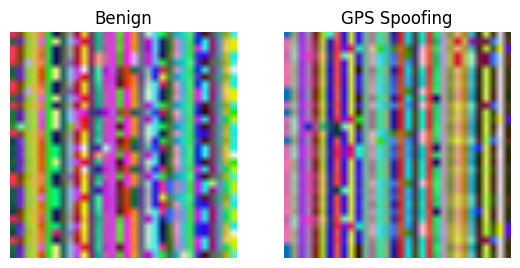

In [33]:
class_names_s = ['Benign', 'GPS Spoofing']

all_predictions_ResNet50 = []
all_label_ResNet50 = []
for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)

all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)

report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

val_ds (ResNet50)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       640
GPS Spoofing       1.00      0.97      0.98       486

    accuracy                           0.99      1126
   macro avg       0.99      0.98      0.99      1126
weighted avg       0.99      0.99      0.99      1126

                  
1) Accuracy: 0.9857904085257548
                  
2) Precision: 0.9861369839275659
                  
3) Recall: 0.9857904085257548
                  
4) Average F1-score: 0.985759213338108
                  
5) F1-score for each type of attack: [0.98765432 0.9832636 ]
                  
6) Average ROC AUC: 0.9835390946502058
                  
7) Average PR AUC: 0.9812877807746566
                  
8) Balanced Accuracy: 0.9835390946502058
                  
9) Hinge: 0.5825932504440497
                  
10) Matthews Correlation Coefficient: 0.9713346057825004
                  
11) Jaccard Score: 0.9670781

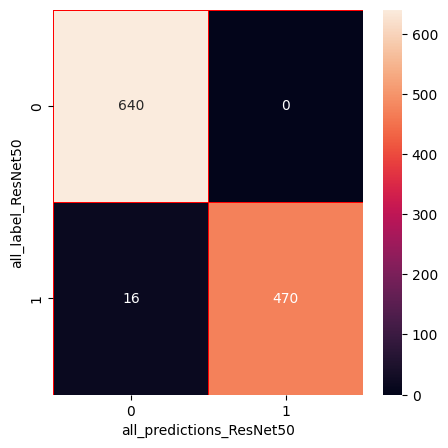

In [34]:
print("val_ds (ResNet50)")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [35]:
loss_val_ResNet50, accuracy_val_ResNet50 = model_ResNet50.evaluate(val_ds)
print("Validation loss: {:.4f}".format(loss_val_ResNet50))
print("Validation accuracy: {:.4f}".format(accuracy_val_ResNet50))

36/36 [==============================] - 1s 34ms/step - loss: 0.0504 - accuracy: 0.9840
Validation loss: 0.0504
Validation accuracy: 0.9840


In [36]:
saved_info = {
    'class_names': class_names,
    'all_label_ResNet50': all_label_ResNet50,
    'all_predictions_ResNet50': all_predictions_ResNet50,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'precision_score': precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'recall_score': recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_weighted': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_each': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Hinge': hinge_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50),
    'Jaccard Score': jaccard_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Log Loss': log_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Zero-One Loss': zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet50_Val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [37]:
with open('ResNet50_Val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label_ResNet50'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet50'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 0 ... 1 0 1]
  
predictions: [0 1 0 ... 1 0 1]
  
cm: [[640   0]
 [ 16 470]]
  
1) Accuracy: 0.9857904085257548
  
2) Precision: 0.9861369839275659
  
3) Recall: 0.9857904085257548
  
4) Average F1-score: 0.985759213338108
  
5) F1-score for each type of attack: [0.98765432 0.9832636 ]
  
6) Average ROC AUC: 0.9835390946502058
  
7) Average PR AUC: 0.9812877807746566
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5825932504440497
  
10) Matthews Correlation Coefficient: 0.9713346057825004
  
11) Jaccard Score: 0.9670781893004116
  
12) Log Loss: 0.5121655898986454
  
13) Zero-One Loss: 0.014209591474245165
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## TL (ResNet50)

In [38]:
base_model_ResNet50.trainable = True
print("Number of layers in the base model: ", len(base_model_ResNet50.layers))
fine_tune_at_ResNet50 = int((130/151)*len(base_model_ResNet50.layers))
for layer in base_model_ResNet50.layers[:fine_tune_at_ResNet50]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_ResNet50 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_ResNet50+1,len(base_model_ResNet50.layers)))

Number of layers in the base model:  175
frozen layers in the base model from layer 1 to  150
unfrozen layers in the base model from 151 to 175 


In [39]:
history= LossHistory()
savepath='./ResNet50+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')
model_ResNet50.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_ResNet50.summary()
len(model_ResNet50.trainable_variables)

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem (  (None, 224, 224, 3)       0         
 SlicingOpLambda)                                                
                                                                 
 tf.nn.bias_add (TFOpLambda  (None, 224, 224, 3)       0         
 )                                                               
                                                                 
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (  (None, 2048)              0     

32

In [40]:
%%time
fine_tune_epochs =5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_ResNet50 = model_ResNet50.fit(train_ds, epochs=total_epochs, initial_epoch=history_ResNet50.epoch[-1],
                         validation_data=val_ds,
                         callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_ResNet50.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0279 - accuracy: 0.9903
Epoch 5: val_loss improved from inf to 0.01541, saving model to ./ResNet50+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 21s 60ms/step - loss: 0.0279 - accuracy: 0.9903 - val_loss: 0.0154 - val_accuracy: 0.9885
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0075 - accuracy: 0.9975
Epoch 6: val_loss improved from 0.01541 to 0.00403, saving model to ./ResNet50+TL.h5
213/213 [==============================] - 12s 56ms/step - loss: 0.0075 - accuracy: 0.9975 - val_loss: 0.0040 - val_accuracy: 0.9956
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0027 - accuracy: 0.9990
Epoch 7: val_loss improved from 0.00403 to 0.00258, saving model to ./ResNet50+TL.h5
213/213 [==============================] - 12s 56ms/step - loss: 0.0027 - accuracy: 0.9990 - val_loss: 0.0026 - val_accuracy: 0.9982
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0026 - accuracy: 0.9990
Epoch 8: val_loss improved from 0.00258 to 0.00082, saving model to ./ResNet50+TL.h5
213/213 [==============================] - 12s 58ms/step -

## ResNet50 Graph

In [41]:
acc_ResNet50 += history_fine_ResNet50.history['accuracy']
val_acc_ResNet50 += history_fine_ResNet50.history['val_accuracy']
loss_ResNet50 += history_fine_ResNet50.history['loss']
val_loss_ResNet50 += history_fine_ResNet50.history['val_loss']

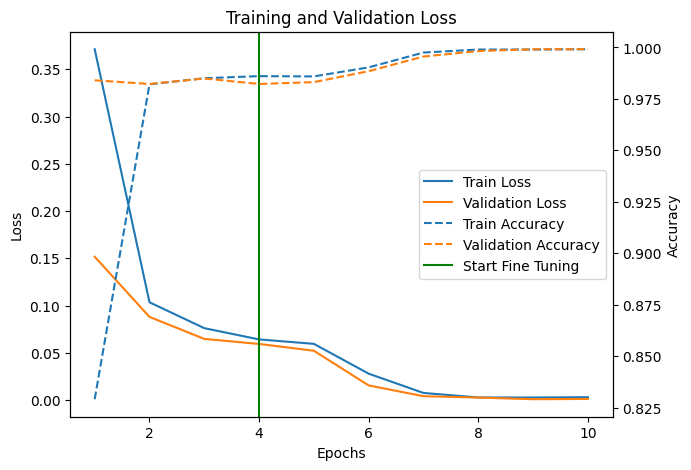

In [42]:
actual_epochs = range(1, total_epochs + 1)  
actual_train_loss = loss_ResNet50[:total_epochs]  
actual_val_loss = val_loss_ResNet50[:total_epochs]  
actual_train_accuracy = acc_ResNet50[:total_epochs]  
actual_val_accuracy = val_acc_ResNet50[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('ResNet50+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('ResNet50+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('ResNet50+Start Fine Tuning.svg', format='svg')
plt.savefig('ResNet50+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

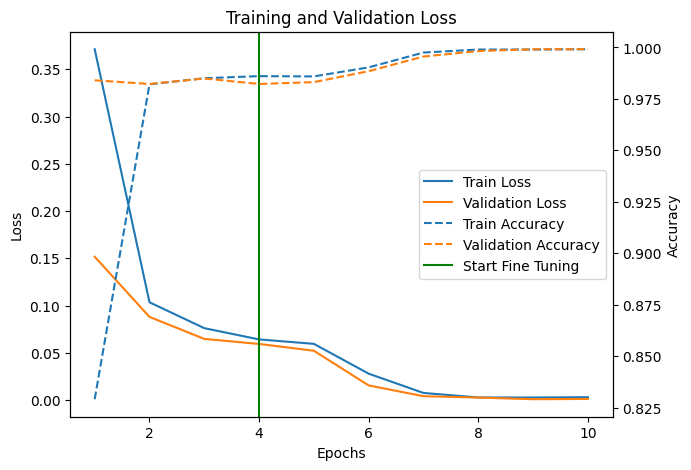

Training Loss: [0.37131693959236145, 0.10343648493289948, 0.07604871690273285, 0.06413713097572327, 0.059432826936244965, 0.02786942943930626, 0.007456258404999971, 0.002676804317161441, 0.0026347036473453045, 0.00295049324631691]
Validation Loss: [0.1516704559326172, 0.08796269446611404, 0.06467316299676895, 0.05932723730802536, 0.05214216560125351, 0.015406426042318344, 0.004033667501062155, 0.002577654318884015, 0.000823832640890032, 0.0011118324473500252]
Training Accuracy: [0.8290497660636902, 0.9820825457572937, 0.9850198030471802, 0.9860478639602661, 0.9859009981155396, 0.9903069734573364, 0.9975032806396484, 0.9989719390869141, 0.9989719390869141, 0.9991188049316406]
Validation Accuracy: [0.9840142130851746, 0.9822379946708679, 0.9849023222923279, 0.9822379946708679, 0.9831261038780212, 0.9884546995162964, 0.9955595135688782, 0.9982237815856934, 0.9991118907928467, 0.9991118907928467]


In [43]:
with open('ResNet50+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
    
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']

plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']

print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds(ResNet50) + TL

Predictions:
 [1 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 0 0 1 0 0 1
 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1
 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1
 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 0 1
 1 0 1 0 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 0 0 0
 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0
 0 1 0 1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 0 0 0 0
 1 1 1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1
 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 1 1
 1 1 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 0 1 1 1 1
 0 1 0 0 0 

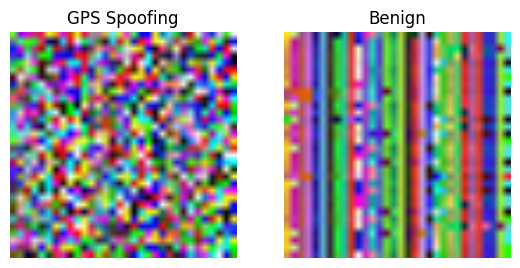

In [44]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet50 = []
all_label_ResNet50 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)

all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)
report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

Test_ds (ResNet50) + TL
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       325
GPS Spoofing       1.00      1.00      1.00       251

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5642361111111112
                  
10) Matthews Correlation Coefficient: 1.0
  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overhead : 0.4097
 

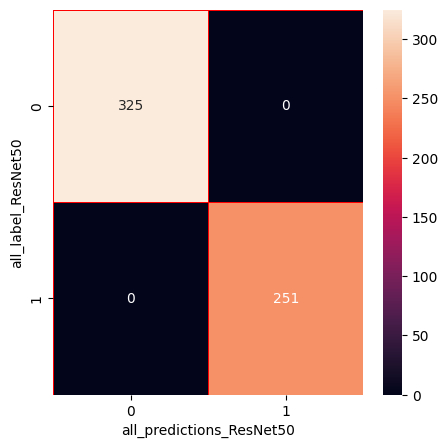

In [45]:
print("Test_ds (ResNet50) + TL")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [46]:
loss_test_ResNet50, accuracy_test_ResNet50 = model_ResNet50.evaluate(test_ds) 
print("Test Loss: {:.4f}".format(loss_test_ResNet50))
print("Test Accuracy: {:.4f}".format(accuracy_test_ResNet50))

18/18 [==============================] - 1s 35ms/step - loss: 0.0010 - accuracy: 1.0000
Test Loss: 0.0010
Test Accuracy: 1.0000


In [47]:
saved_info = {
    'class_names': class_names,
    'all_label_ResNet50': all_label_ResNet50,
    'all_predictions_ResNet50': all_predictions_ResNet50,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'precision_score': precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'recall_score': recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_weighted': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_each': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Hinge': hinge_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50),
    'Jaccard Score': jaccard_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Log Loss': log_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Zero-One Loss': zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet50 + TL_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [48]:
#=========

In [49]:
with open('ResNet50 + TL_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label_ResNet50'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet50'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 0 0 1 0 0 1
 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1
 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1
 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 0 1
 1 0 1 0 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 0 0 0
 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0
 0 1 0 1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 0 0 0 0
 1 1 1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1
 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 1 1
 1 1 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 0

## Val_ds + TL (ResNet50)

Predictions:
 [1 1 0 ... 1 1 1]
Label:
 [1 1 0 ... 1 1 1]


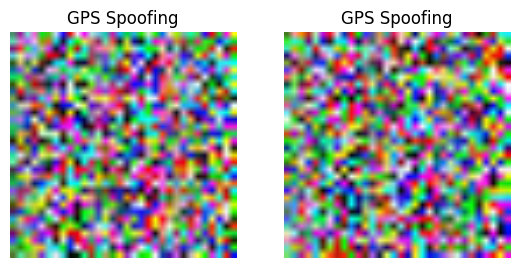

In [50]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet50 = []
all_label_ResNet50 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)

all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)

report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

val_ds (ResNet50)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       644
GPS Spoofing       1.00      1.00      1.00       482

    accuracy                           1.00      1126
   macro avg       1.00      1.00      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5719360568383659
                  
10) Matthews Correlation Coefficient: 1.0
  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overhead : 0.4097
       

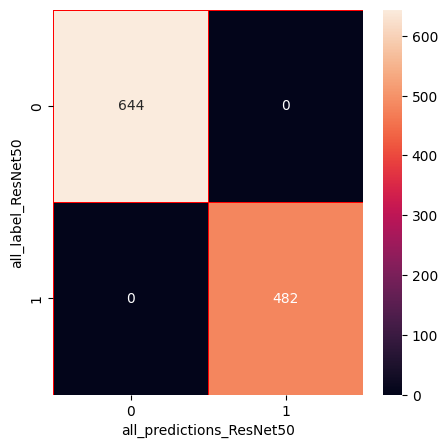

In [51]:
print("val_ds (ResNet50)")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [52]:
loss_val_ResNet50, accuracy_val_ResNet50 = model_ResNet50.evaluate(val_ds) 
print("Validation loss: {:.4f}".format(loss_val_ResNet50))
print("Validation accuracy: {:.4f}".format(accuracy_val_ResNet50))

36/36 [==============================] - 2s 36ms/step - loss: 8.0054e-05 - accuracy: 1.0000
Validation loss: 0.0001
Validation accuracy: 1.0000


In [53]:
saved_info = {
    'class_names': class_names,
    'all_label_ResNet50': all_label_ResNet50,
    'all_predictions_ResNet50': all_predictions_ResNet50,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'precision_score': precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'recall_score': recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_weighted': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'f1_score_each': f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Hinge': hinge_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50),
    'Jaccard Score': jaccard_score(all_label_ResNet50 , all_predictions_ResNet50),
    'Log Loss': log_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Zero-One Loss': zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet50_Val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [54]:
#=========

In [55]:
with open('ResNet50_Val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label_ResNet50'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet50'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 0 ... 1 1 1]
  
predictions: [1 1 0 ... 1 1 1]
  
cm: [[644   0]
 [  0 482]]
  
1) Accuracy: 1.0
  
2) Precision: 1.0
  
3) Recall: 1.0
  
4) Average F1-score: 1.0
  
5) F1-score for each type of attack: [1. 1.]
  
6) Average ROC AUC: 1.0
  
7) Average PR AUC: 1.0
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5719360568383659
  
10) Matthews Correlation Coefficient: 1.0
  
11) Jaccard Score: 1.0
  
12) Log Loss: 2.2204460492503136e-16
  
13) Zero-One Loss: 0.0
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## ResNet 50 config

In [56]:
new_model = tf.keras.models.load_model('./ResNet50+TL.h5')

In [57]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_2
sequential
tf.__operators__.getitem
tf.nn.bias_add
resnet50
[[[[ 2.82526277e-02 -1.18737184e-02  1.51488732e-03 ... -1.07003953e-02
    -5.27982824e-02 -1.36667420e-03]
   [ 5.86827798e-03  5.04415408e-02  3.46324709e-03 ...  1.01423981e-02
     1.39493728e-02  1.67549420e-02]
   [-2.44090753e-03 -4.86173332e-02  2.69966386e-03 ... -3.44439060e-04
     3.48098315e-02  6.28910400e-03]]

  [[ 1.81872323e-02 -7.20698107e-03  4.80302610e-03 ... -7.43396254e-03
    -8.56800564e-03  1.16849300e-02]
   [ 1.87554304e-02  5.12730293e-02  4.50406177e-03 ...  1.39413681e-02
     1.26296384e-02 -1.73004344e-02]
   [ 1.90453827e-02 -3.87909152e-02  4.25842637e-03 ...  2.75742816e-04
    -1.27962548e-02 -8.35626759e-03]]

  [[ 1.58849321e-02 -1.06073255e-02  1.30999666e-02 ... -2.26797583e-03
    -3.98984266e-04  3.39989027e-04]
   [ 3.61421369e-02  5.02430499e-02  1.22699486e-02 ...  1.19910473e-02
     2.02837810e-02 -1.96981970e-02]
   [ 2.17959806e-02 -3.86004597e-02  1.12379901e-02 ... 

In [58]:
print(new_model.get_config())

{'name': 'model', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_2'}, 'registered_name': None, 'name': 'input_2', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float32', 

# ResNet152 model

In [237]:
IMG_SHAPE = (img_height, img_width,3)
base_model_ResNet152 = tf.keras.applications.ResNet152(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [238]:
base_model_ResNet152.trainable = False
base_model_ResNet152.summary()

Model: "resnet152"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_11 (InputLayer)       [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_11[0][0]']            
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                      

                                                                                                  
 conv3_block6_2_bn (BatchNormal  (None, 28, 28, 128)  512        ['conv3_block6_2_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv3_block6_2_relu (Activatio  (None, 28, 28, 128)  0          ['conv3_block6_2_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv3_block6_3_conv (Conv2D)   (None, 28, 28, 512)  66048       ['conv3_block6_2_relu[0][0]']    
                                                                                                  
 conv3_block6_3_bn (BatchNormal  (None, 28, 28, 512)  2048       ['conv3_block6_3_conv[0][0]']    
 ization) 

 n)                                                                                               
                                                                                                  
 conv4_block1_0_conv (Conv2D)   (None, 14, 14, 1024  525312      ['conv3_block8_out[0][0]']       
                                )                                                                 
                                                                                                  
 conv4_block1_3_conv (Conv2D)   (None, 14, 14, 1024  263168      ['conv4_block1_2_relu[0][0]']    
                                )                                                                 
                                                                                                  
 conv4_block1_0_bn (BatchNormal  (None, 14, 14, 1024  4096       ['conv4_block1_0_conv[0][0]']    
 ization)                       )                                                                 
          

                                                                                                  
 conv4_block4_2_conv (Conv2D)   (None, 14, 14, 256)  590080      ['conv4_block4_1_relu[0][0]']    
                                                                                                  
 conv4_block4_2_bn (BatchNormal  (None, 14, 14, 256)  1024       ['conv4_block4_2_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv4_block4_2_relu (Activatio  (None, 14, 14, 256)  0          ['conv4_block4_2_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv4_block4_3_conv (Conv2D)   (None, 14, 14, 1024  263168      ['conv4_block4_2_relu[0][0]']    
          

 n)                                                                                               
                                                                                                  
 conv4_block7_2_conv (Conv2D)   (None, 14, 14, 256)  590080      ['conv4_block7_1_relu[0][0]']    
                                                                                                  
 conv4_block7_2_bn (BatchNormal  (None, 14, 14, 256)  1024       ['conv4_block7_2_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv4_block7_2_relu (Activatio  (None, 14, 14, 256)  0          ['conv4_block7_2_bn[0][0]']      
 n)                                                                                               
                                                                                                  
 conv4_blo

 conv4_block10_1_relu (Activati  (None, 14, 14, 256)  0          ['conv4_block10_1_bn[0][0]']     
 on)                                                                                              
                                                                                                  
 conv4_block10_2_conv (Conv2D)  (None, 14, 14, 256)  590080      ['conv4_block10_1_relu[0][0]']   
                                                                                                  
 conv4_block10_2_bn (BatchNorma  (None, 14, 14, 256)  1024       ['conv4_block10_2_conv[0][0]']   
 lization)                                                                                        
                                                                                                  
 conv4_block10_2_relu (Activati  (None, 14, 14, 256)  0          ['conv4_block10_2_bn[0][0]']     
 on)                                                                                              
          

... (6 outputs left out)

                                )                                                                 
                                                                                                  
 conv4_block31_1_conv (Conv2D)  (None, 14, 14, 256)  262400      ['conv4_block30_out[0][0]']      
                                                                                                  
 conv4_block31_1_bn (BatchNorma  (None, 14, 14, 256)  1024       ['conv4_block31_1_conv[0][0]']   
 lization)                                                                                        
                                                                                                  
 conv4_block31_1_relu (Activati  (None, 14, 14, 256)  0          ['conv4_block31_1_bn[0][0]']     
 on)                                                                                              
                                                                                                  
 conv4_blo

 conv4_block33_out (Activation)  (None, 14, 14, 1024  0          ['conv4_block33_add[0][0]']      
                                )                                                                 
                                                                                                  
 conv4_block34_1_conv (Conv2D)  (None, 14, 14, 256)  262400      ['conv4_block33_out[0][0]']      
                                                                                                  
 conv4_block34_1_bn (BatchNorma  (None, 14, 14, 256)  1024       ['conv4_block34_1_conv[0][0]']   
 lization)                                                                                        
                                                                                                  
 conv4_block34_1_relu (Activati  (None, 14, 14, 256)  0          ['conv4_block34_1_bn[0][0]']     
 on)                                                                                              
          

                                                                                                  
 conv4_block36_out (Activation)  (None, 14, 14, 1024  0          ['conv4_block36_add[0][0]']      
                                )                                                                 
                                                                                                  
 conv5_block1_1_conv (Conv2D)   (None, 7, 7, 512)    524800      ['conv4_block36_out[0][0]']      
                                                                                                  
 conv5_block1_1_bn (BatchNormal  (None, 7, 7, 512)   2048        ['conv5_block1_1_conv[0][0]']    
 ization)                                                                                         
                                                                                                  
 conv5_block1_1_relu (Activatio  (None, 7, 7, 512)   0           ['conv5_block1_1_bn[0][0]']      
 n)       

                                                                  'conv5_block3_3_bn[0][0]']      
                                                                                                  
 conv5_block3_out (Activation)  (None, 7, 7, 2048)   0           ['conv5_block3_add[0][0]']       
                                                                                                  
Total params: 58,370,944
Trainable params: 0
Non-trainable params: 58,370,944
__________________________________________________________________________________________________


In [239]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_ResNet152 = base_model_ResNet152(image_batch)
print(feature_batch_ResNet152.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_ResNet152 = global_average_layer(feature_batch_ResNet152)
print(feature_batch_average_ResNet152.shape)
prediction_layer_ResNet152 = tf.keras.layers.Dense(1)
prediction_batch_ResNet152 = prediction_layer_ResNet152(feature_batch_average_ResNet152)
print(prediction_batch_ResNet152.shape)

(32, 7, 7, 2048)
(32, 2048)
(32, 1)


In [240]:
inputs_ResNet152 = tf.keras.Input(shape=(img_height, img_width,3))
x_ResNet152 = data_augmentation(inputs_ResNet152)
x_ResNet152 = tf.keras.applications.resnet.preprocess_input (x_ResNet152)
x_ResNet152 = base_model_ResNet152(x_ResNet152, training=False)  
x_ResNet152 = global_average_layer(x_ResNet152)
x_ResNet152 = tf.keras.layers.Dropout(0.2)(x_ResNet152)
outputs_ResNet152 = prediction_layer_ResNet152(x_ResNet152)
model_ResNet152 = tf.keras.Model(inputs_ResNet152, outputs_ResNet152)

In [241]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [242]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./ResNet152.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1,save_best_only=True, mode='auto')
model_ResNet152.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [243]:
model_ResNet152.summary()

Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_12 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_3  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_3 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 resnet152 (Functional)      (None, 7, 7, 2048)        58370944  
                                                                 
 global_average_pooling2d_5  (None, 2048)              0   

In [244]:
initial_epochs = 5
loss0, accuracy0 = model_ResNet152.evaluate(val_ds)

36/36 [==============================] - 8s 83ms/step - loss: 1.2809 - accuracy: 0.0311


In [245]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 1.2809
initial accuracy: 0.0311


In [246]:
%%time
history_ResNet152 = model_ResNet152.fit(train_ds, epochs=initial_epochs, validation_data=val_ds,
                    callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_ResNet152.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
213/213 [==============================] - ETA: 0s - loss: 0.4392 - accuracy: 0.7870
Epoch 1: val_loss improved from inf to 0.19641, saving model to ./ResNet152.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 32s 118ms/step - loss: 0.4392 - accuracy: 0.7870 - val_loss: 0.1964 - val_accuracy: 0.9121
Epoch 2/5
213/213 [==============================] - ETA: 0s - loss: 0.1115 - accuracy: 0.9764
Epoch 2: val_loss improved from 0.19641 to 0.10512, saving model to ./ResNet152.h5
213/213 [==============================] - 24s 112ms/step - loss: 0.1115 - accuracy: 0.9764 - val_loss: 0.1051 - val_accuracy: 0.9671
Epoch 3/5
213/213 [==============================] - ETA: 0s - loss: 0.0686 - accuracy: 0.9846
Epoch 3: val_loss improved from 0.10512 to 0.08842, saving model to ./ResNet152.h5
213/213 [==============================] - 24s 113ms/step - loss: 0.0686 - accuracy: 0.9846 - val_loss: 0.0884 - val_accuracy: 0.9813
Epoch 4/5
213/213 [==============================] - ETA: 0s - loss: 0.0532 - accuracy: 0.9865
Epoch 4: val_loss improved from 0.08842 to 0.06386, saving model to ./ResNet152.h5
213/213 [==============================] - 23s 109ms/step - loss

In [247]:
acc_ResNet152 = history_ResNet152.history['accuracy']
val_acc_ResNet152 = history_ResNet152.history['val_accuracy']
loss_ResNet152 = history_ResNet152.history['loss']
val_loss_ResNet152 = history_ResNet152.history['val_loss']

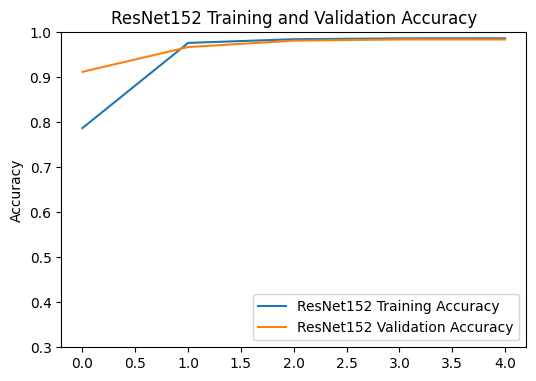

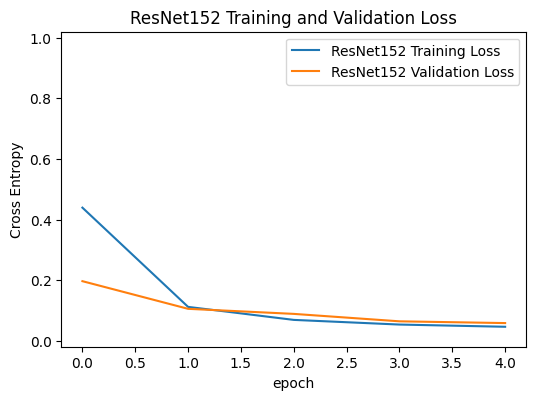

In [248]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_ResNet152, label='ResNet152 Training Accuracy')
plt.plot(val_acc_ResNet152, label='ResNet152 Validation Accuracy')
plt.ylim([0.3, 1.01])
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('ResNet152 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_ResNet152, label='ResNet152 Training Loss')
plt.plot(val_loss_ResNet152, label='ResNet152 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([-0.02, 1.02])
plt.title('ResNet152 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('ResNet152_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('ResNet152_TL+ORG.svg', format='svg')
plt.savefig('ResNet152_TL+ORG.png', format='png', dpi=300)
plt.show()

## Test_ds (ResNet152)

Predictions:
 [0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 1 1
 1 0 0 1 1 0 1 1 0 0 0 0 1 1 0 1 0 0 1 1 1 1 1 0 1 1 0 1 0 0 1 1 1 0 1 1 0
 0 0 1 1 1 1 1 1 1 0 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1 1 1 1 0 0 0 0
 0 0 0 0 0 1 1 1 0 0 0 1 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0
 0 0 0 0 0 1 1 1 1 1 1 1 1 0 1 0 1 1 0 0 1 1 1 0 0 1 1 0 0 0 0 0 1 0 0 1 0
 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 1 0 0 1 1 0 1 1 1 1
 1 0 0 1 1 0 0 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 1 0 1 1 1 1 1 0 0
 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 1
 0 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0
 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 1
 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1
 1 1 1 0 0 0 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0
 1 1 0 1 0 1 0 1 0 1 0 1 0 0 1 1 1 1 0 1 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 1 0
 1 1 0 0 1 

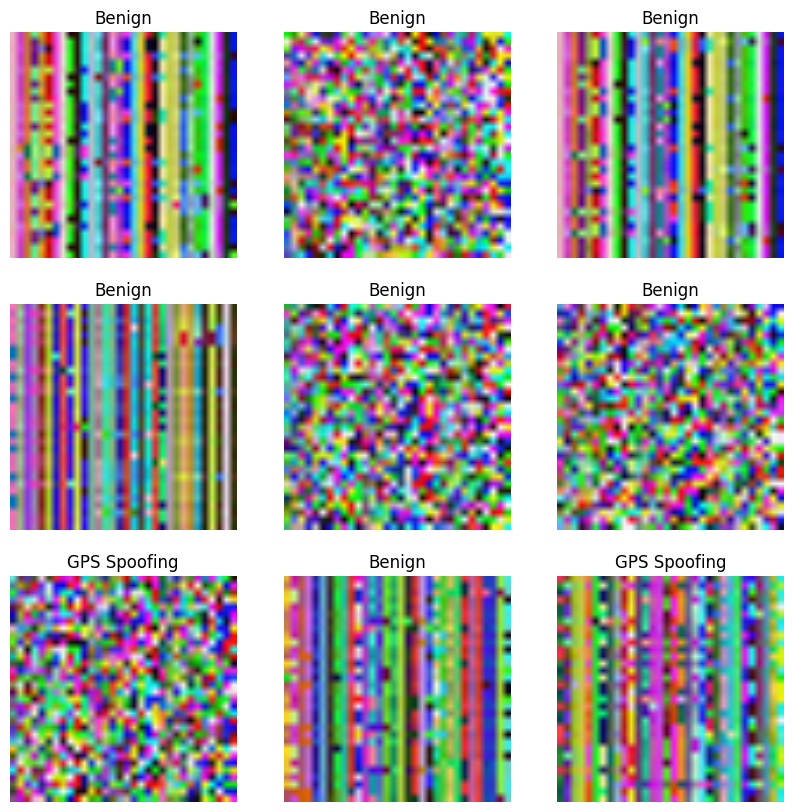

In [249]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)

all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)

report_ResNet152 = classification_report(all_labels_ResNet152, all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

In [250]:
cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
TP = np.sum((all_predictions_ResNet152 == 1) & (all_labels_ResNet152 == 1))
FP = np.sum((all_predictions_ResNet152 == 1) & (all_labels_ResNet152 == 0))
FN = np.sum((all_predictions_ResNet152 == 0) & (all_labels_ResNet152 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_ResNet152)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_ResNet152, all_predictions_ResNet152).ravel()
specificity = TN / (TN + FP)

test_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99       327
GPS Spoofing       1.00      0.98      0.99       249

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9930555555555556
                  
2) Precision: 0.9931394763343404
                  
3) Recall: 0.9930555555555556
                  
4) Average F1-score: 0.9930485481297351
                  
5) F1-score for each type of attack: [0.99392097 0.99190283]
                  
6) Average ROC AUC: 0.9919678714859438
                  
7) Average PR AUC: 0.990880187416332
                  
8) Balanced Accuracy: 0.9919678714859438
                  
9) Hinge: 0.5746527777777778
                  
10) Matthews Correlation Coefficient: 0.985923567433688
                  
11) Jaccard Score: 0.983935

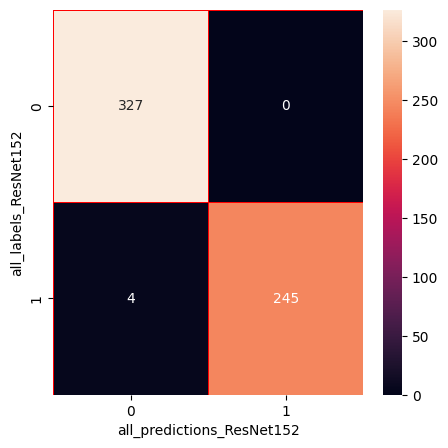

In [251]:
print("test_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152 , all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet152")
plt.ylabel("all_labels_ResNet152")
plt.show()

In [252]:
loss_test_ResNet152, accuracy_test_ResNet152 = model_ResNet152.evaluate(test_ds)
print("Test Loss: {:.4f}".format(loss_test_ResNet152))
print("Test Accuracy: {:.4f}".format(accuracy_test_ResNet152))

18/18 [==============================] - 2s 80ms/step - loss: 0.0514 - accuracy: 0.9861
Test Loss: 0.0514
Test Accuracy: 0.9861


In [253]:
saved_info = {
    'class_names': class_names,
    'all_labels_ResNet152': all_labels_ResNet152,
    'all_predictions_ResNet152': all_predictions_ResNet152,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'precision_score': precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'recall_score': recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_each': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Hinge': hinge_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152),
    'Jaccard Score': jaccard_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Log Loss': log_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Zero-One Loss': zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet152_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [254]:
with open('ResNet152_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_ResNet152'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet152'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 1 1 1 1 1
 1 0 0 1 1 0 1 1 0 0 0 0 1 1 0 1 0 0 1 1 1 1 1 0 1 1 0 1 0 0 1 1 1 0 1 1 0
 0 0 1 1 1 1 1 1 1 0 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1 1 1 1 0 0 0 0
 0 0 0 0 0 1 1 1 0 0 0 1 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0
 0 0 0 0 0 1 1 1 1 1 1 1 1 0 1 0 1 1 0 0 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 1 1
 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 1 0 0 1 1 0 1 1 1 1
 1 0 0 1 1 0 0 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 1 0 1 1 1 1 1 0 0
 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 1
 0 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0
 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 1
 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1
 1 1 1 0 0 0 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0
 1 1 0 1 0 1 0 1 0 1 0 1 0 0 1 1 1 1 0 1 0 1 0 1 0 0 1 0 0 0 0 1 0

## VAL_ds (ResNet152)

Predictions:
 [1 1 0 ... 1 0 0]
Labels:
 [1 1 0 ... 1 0 0]


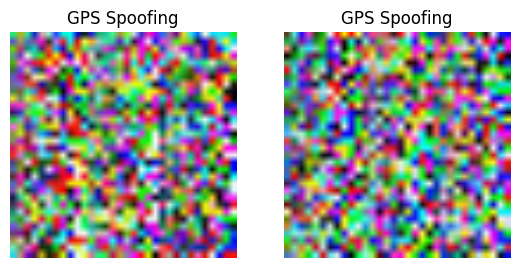

In [255]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)

all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)

report_ResNet152 = classification_report(all_labels_ResNet152 , all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

In [256]:
loss_val_ResNet152, accuracy_val_ResNet152 = model_ResNet152.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_ResNet152))
print("Validation Accuracy: {:.4f}".format(accuracy_val_ResNet152))

36/36 [==============================] - 4s 81ms/step - loss: 0.0593 - accuracy: 0.9822
Validation Loss: 0.0593
Validation Accuracy: 0.9822


val_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       646
GPS Spoofing       1.00      0.96      0.98       480

    accuracy                           0.98      1126
   macro avg       0.99      0.98      0.98      1126
weighted avg       0.99      0.98      0.98      1126

                  
1) Accuracy: 0.9849023090586145
                  
2) Precision: 0.985289429339163
                  
3) Recall: 0.9849023090586145
                  
4) Average F1-score: 0.9848642586607096
                  
5) F1-score for each type of attack: [0.98701299 0.98197243]
                  
6) Average ROC AUC: 0.9822916666666667
                  
7) Average PR AUC: 0.9796810242747188
                  
8) Balanced Accuracy: 0.9822916666666667
                  
9) Hinge: 0.588809946714032
                  
10) Matthews Correlation Coefficient: 0.9694588322102323
                  
11) Jaccard Score: 0.9645833

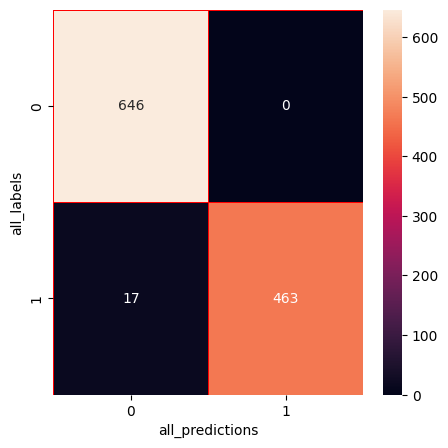

In [257]:
print("val_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [258]:
saved_info = {
    'class_names': class_names,
    'all_labels_ResNet152': all_labels_ResNet152,
    'all_predictions_ResNet152': all_predictions_ResNet152,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'precision_score': precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'recall_score': recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_each': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Hinge': hinge_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152),
    'Jaccard Score': jaccard_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Log Loss': log_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Zero-One Loss': zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet152_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [259]:
with open('ResNet152_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_ResNet152'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet152'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 0 ... 1 0 0]
  
predictions: [1 1 0 ... 1 0 0]
  
cm: [[646   0]
 [ 17 463]]
  
1) Accuracy: 0.9849023090586145
  
2) Precision: 0.985289429339163
  
3) Recall: 0.9849023090586145
  
4) Average F1-score: 0.9848642586607096
  
5) F1-score for each type of attack: [0.98701299 0.98197243]
  
6) Average ROC AUC: 0.9822916666666667
  
7) Average PR AUC: 0.9796810242747188
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.588809946714032
  
10) Matthews Correlation Coefficient: 0.9694588322102323
  
11) Jaccard Score: 0.9645833333333333
  
12) Log Loss: 0.5441759392673107
  
13) Zero-One Loss: 0.015097690941385467
  
14) Prediction Overhead: 0.4253472222222222
  
15) Specificity: 1.0


## TL (ResNet152)

In [260]:
base_model_ResNet152.trainable = True
print("Number of layers in the base model: ", len(base_model_ResNet152.layers))
fine_tune_at_ResNet152 = int((130/151)*len(base_model_ResNet152.layers))
for layer in base_model_ResNet152.layers[:fine_tune_at_ResNet152]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_ResNet152 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_ResNet152+1,len(base_model_ResNet152.layers)))

Number of layers in the base model:  515
frozen layers in the base model from layer 1 to  443
unfrozen layers in the base model from 444 to 515 


In [261]:
history= LossHistory()
savepath='./ResNet152+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1,save_best_only=True, mode='auto')
model_ResNet152.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_ResNet152.summary()
len(model_ResNet152.trainable_variables)

Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_12 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_3  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_3 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 resnet152 (Functional)      (None, 7, 7, 2048)        58370944  
                                                                 
 global_average_pooling2d_5  (None, 2048)              0   

90

In [262]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_ResNet152 = model_ResNet152.fit(train_ds, epochs=total_epochs, initial_epoch=history_ResNet152.epoch[-1],
                         validation_data=val_ds,
                         callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_ResNet152.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0196 - accuracy: 0.9934
Epoch 5: val_loss improved from inf to 0.02792, saving model to ./ResNet152+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 48s 152ms/step - loss: 0.0196 - accuracy: 0.9934 - val_loss: 0.0279 - val_accuracy: 0.9858
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0059 - accuracy: 0.9985
Epoch 6: val_loss improved from 0.02792 to 0.00339, saving model to ./ResNet152+TL.h5
213/213 [==============================] - 29s 137ms/step - loss: 0.0059 - accuracy: 0.9985 - val_loss: 0.0034 - val_accuracy: 0.9991
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0079 - accuracy: 0.9971
Epoch 7: val_loss improved from 0.00339 to 0.00283, saving model to ./ResNet152+TL.h5
213/213 [==============================] - 31s 143ms/step - loss: 0.0079 - accuracy: 0.9971 - val_loss: 0.0028 - val_accuracy: 0.9991
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0031 - accuracy: 0.9988
Epoch 8: val_loss did not improve from 0.00283
213/213 [==============================] - 29s 135ms/step - loss: 0.0031 - accuracy: 0.9988

## ResNet152 Graph

In [263]:
acc_ResNet152 += history_fine_ResNet152.history['accuracy']
val_acc_ResNet152 += history_fine_ResNet152.history['val_accuracy']
loss_ResNet152 += history_fine_ResNet152.history['loss']
val_loss_ResNet152 += history_fine_ResNet152.history['val_loss']

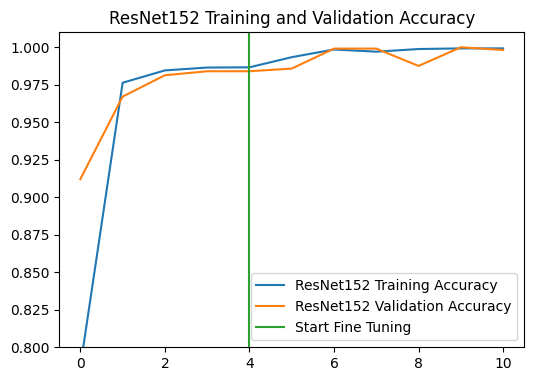

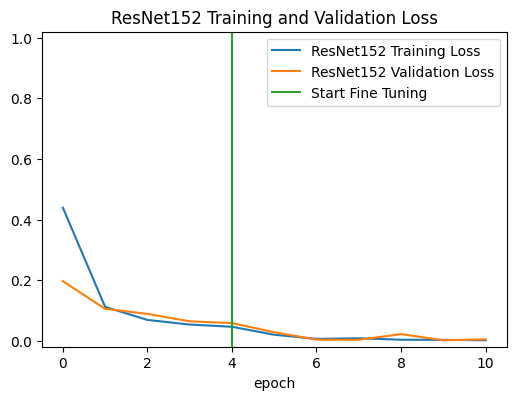

In [264]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_ResNet152, label='ResNet152 Training Accuracy')
plt.plot(val_acc_ResNet152, label='ResNet152 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('ResNet152 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_ResNet152, label='ResNet152 Training Loss')
plt.plot(val_loss_ResNet152, label='ResNet152 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('ResNet152 Training and Validation Loss')
plt.xlabel('epoch')

training_history = {}
training_history['train_loss'] = history_ResNet152.history['loss']
training_history['val_loss'] = history_ResNet152.history['val_loss']
training_history['train_acc'] = history_ResNet152.history['accuracy']
training_history['val_acc'] = history_ResNet152.history['val_accuracy']

with open('ResNet152_TL+ORG.pkl', 'wb') as file:
    pickle.dump(training_history, file)
plt.savefig('ResNet152_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('ResNet152_TL+ORG.svg', format='svg')
plt.savefig('ResNet152_TL+ORG.png', format='png', dpi=300)
plt.show()

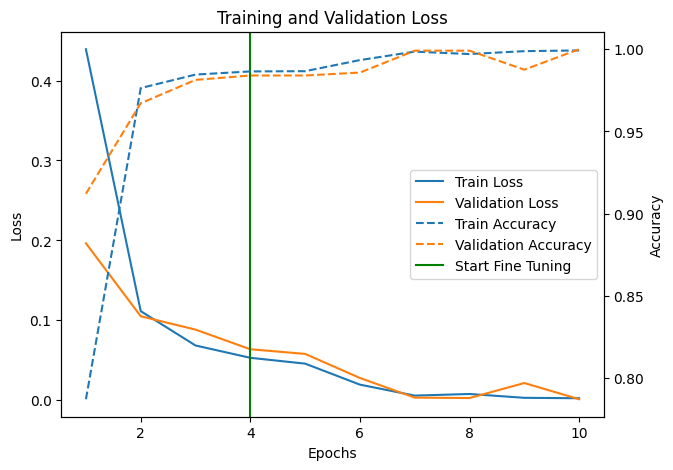

In [265]:
actual_epochs = range(1, total_epochs + 1) 
actual_train_loss = loss_ResNet152[:total_epochs]  
actual_val_loss = val_loss_ResNet152[:total_epochs]  
actual_train_accuracy = acc_ResNet152[:total_epochs]
actual_val_accuracy = val_acc_ResNet152[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')

ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('ResNet152+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('ResNet152+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('ResNet152+Start Fine Tuning.svg', format='svg')
plt.savefig('ResNet152+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

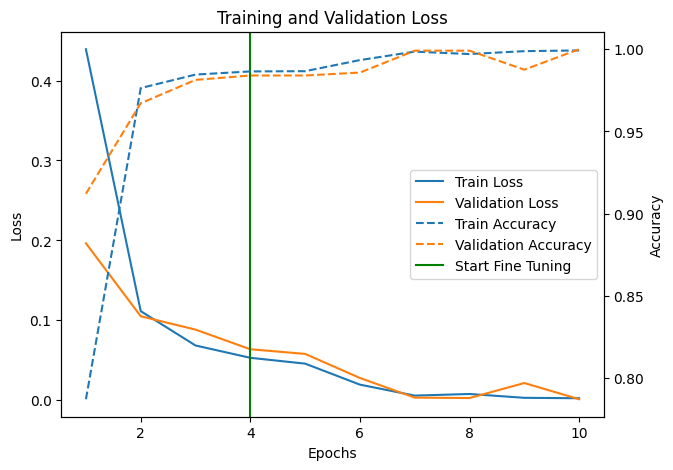

Training Loss: [0.4391500651836395, 0.11151254177093506, 0.06857410818338394, 0.05317068472504616, 0.045882225036621094, 0.019609738141298294, 0.005898462142795324, 0.007923570461571217, 0.003127875505015254, 0.002609978197142482]
Validation Loss: [0.19640767574310303, 0.10511817783117294, 0.0884169489145279, 0.06385762989521027, 0.05806633085012436, 0.027923624962568283, 0.0033870285842567682, 0.0028292136266827583, 0.021618105471134186, 0.0013666520826518536]
Training Accuracy: [0.7870465517044067, 0.9763548374176025, 0.9845792055130005, 0.9864884614944458, 0.9866353273391724, 0.9933910965919495, 0.9985313415527344, 0.9970626831054688, 0.9988250732421875, 0.9992656707763672]
Validation Accuracy: [0.9120781421661377, 0.9671403169631958, 0.9813498854637146, 0.9840142130851746, 0.9840142130851746, 0.9857904314994812, 0.9991118907928467, 0.9991118907928467, 0.9875665903091431, 1.0]


In [266]:
with open('ResNet152+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (ResNet152) + TL

Predictions:
 [0 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 0 1 0 1 1
 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 1 1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 1 0 0 0 1 0
 0 0 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1
 1 0 0 1 1 0 1 0 1 1 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 0 1 1 0 0 0 1 0 1 1 0 0
 0 0 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1
 0 1 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1 1 0 1 1 1 0
 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 1
 1 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 1
 0 0 1 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0
 0 0 1 0 1 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1 0 1 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0
 0 0 1 0 0 1 0 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1
 1 1 0 1 0 

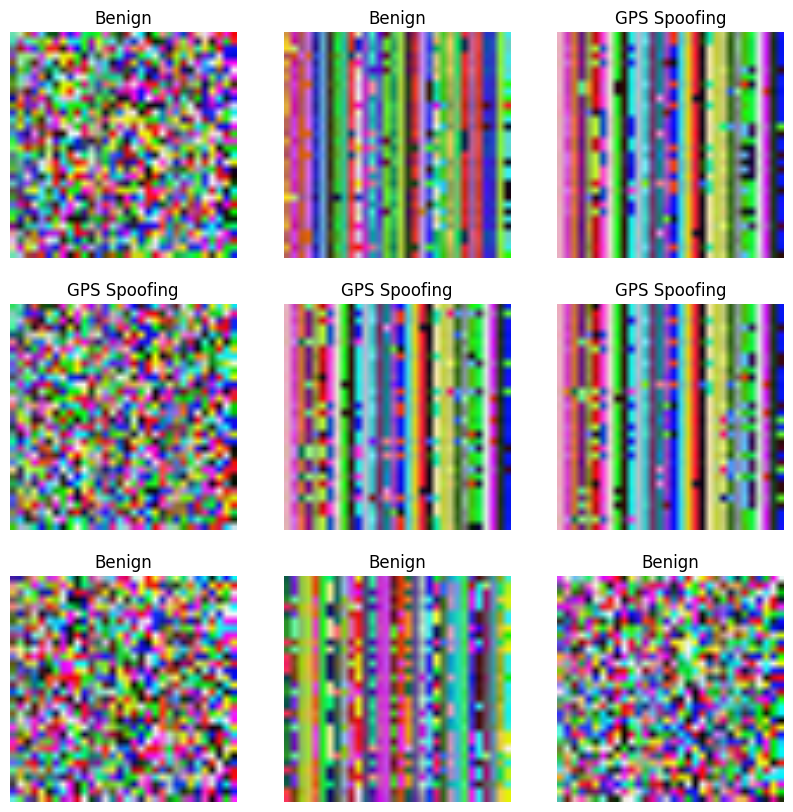

In [267]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)

all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)
report_ResNet152 = classification_report(all_labels_ResNet152 , all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

test_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       340
GPS Spoofing       1.00      1.00      1.00       236

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 0.9982638888888888
                  
2) Precision: 0.9982689801238188
                  
3) Recall: 0.9982638888888888
                  
4) Average F1-score: 0.9982633205612245
                  
5) F1-score for each type of attack: [0.99853157 0.99787686]
                  
6) Average ROC AUC: 0.9978813559322034
                  
7) Average PR AUC: 0.997498822975518
                  
8) Balanced Accuracy: 0.9978813559322034
                  
9) Hinge: 0.5920138888888888
                  
10) Matthews Correlation Coefficient: 0.9964148667144989
                  
11) Jaccard Score: 0.99576

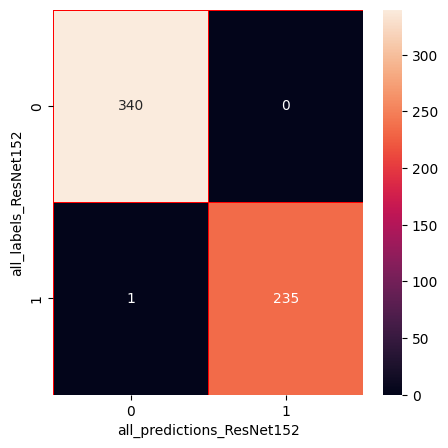

In [268]:
print("test_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152 , all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet152")
plt.ylabel("all_labels_ResNet152")
plt.show()

In [269]:
loss_test_ResNet152, accuracy_test_ResNet152 = model_ResNet152.evaluate(test_ds)
print("Test Loss: {:.4f}".format(loss_test_ResNet152))
print("Test Accuracy: {:.4f}".format(accuracy_test_ResNet152))

18/18 [==============================] - 2s 80ms/step - loss: 0.0064 - accuracy: 0.9965
Test Loss: 0.0064
Test Accuracy: 0.9965


In [270]:
saved_info = {
    'class_names': class_names,
    'all_labels_ResNet152': all_labels_ResNet152,
    'all_predictions_ResNet152': all_predictions_ResNet152,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'precision_score': precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'recall_score': recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_each': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Hinge': hinge_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152),
    'Jaccard Score': jaccard_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Log Loss': log_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Zero-One Loss': zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet152_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [271]:
#=========

In [272]:
with open('ResNet152_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_ResNet152'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet152'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 0 1 0 1 1
 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 1 1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 1 0 0 0 1 0
 0 0 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1 1 0 1 0 0 1
 1 0 0 1 1 0 1 0 1 1 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 0 1 1 0 0 0 1 0 1 1 0 0
 0 0 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1
 0 1 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1 1 0 1 1 1 0
 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 1
 1 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 1
 0 0 1 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 1 1 1 1 1 0 1 0
 0 0 1 0 1 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1 0 1 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0
 0 0 1 0 0 1 0 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0

## Val_ds (ResNet152) + TL

Predictions:
 [0 0 1 ... 0 0 0]
Labels:
 [0 0 1 ... 0 0 0]


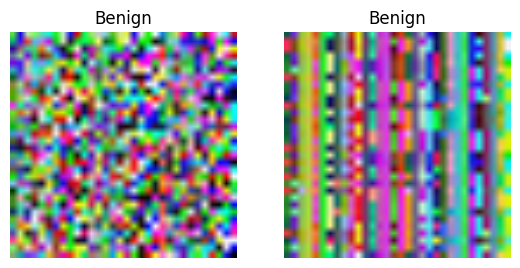

In [273]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)
    
all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)

report_ResNet152 = classification_report(all_labels_ResNet152 , all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

val_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       649
GPS Spoofing       1.00      1.00      1.00       477

    accuracy                           1.00      1126
   macro avg       1.00      1.00      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 0.9991119005328597
                  
2) Precision: 0.9991132668397322
                  
3) Recall: 0.9991119005328597
                  
4) Average F1-score: 0.9991117764231782
                  
5) F1-score for each type of attack: [0.99923018 0.99895068]
                  
6) Average ROC AUC: 0.9989517819706499
                  
7) Average PR AUC: 0.9987916634084401
                  
8) Balanced Accuracy: 0.9989517819706499
                  
9) Hinge: 0.5772646536412078
                  
10) Matthews Correlation Coefficient: 0.9981825122136144
                  
11) Jaccard Score: 0.99790

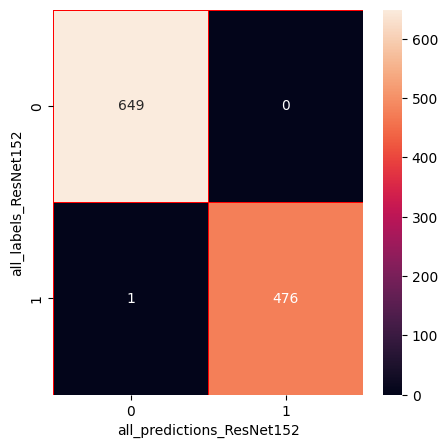

In [274]:
print("val_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152 , all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet152")
plt.ylabel("all_labels_ResNet152")
plt.show()

In [275]:
loss_val_ResNet152, accuracy_val_ResNet152 = model_ResNet152.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_ResNet152))
print("Validation Accuracy: {:.4f}".format(accuracy_val_ResNet152))

36/36 [==============================] - 5s 81ms/step - loss: 0.0043 - accuracy: 0.9982
Validation Loss: 0.0043
Validation Accuracy: 0.9982


In [276]:
saved_info = {
    'class_names': class_names,
    'all_labels_ResNet152': all_labels_ResNet152,
    'all_predictions_ResNet152': all_predictions_ResNet152,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'precision_score': precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'recall_score': recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'f1_score_each': f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Hinge': hinge_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152),
    'Jaccard Score': jaccard_score(all_labels_ResNet152, all_predictions_ResNet152),
    'Log Loss': log_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Zero-One Loss': zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('ResNet152_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [277]:
#=========

In [278]:
with open('ResNet152_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_ResNet152'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet152'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 1 ... 0 0 0]
  
predictions: [0 0 1 ... 0 0 0]
  
cm: [[649   0]
 [  1 476]]
  
1) Accuracy: 0.9991119005328597
  
2) Precision: 0.9991132668397322
  
3) Recall: 0.9991119005328597
  
4) Average F1-score: 0.9991117764231782
  
5) F1-score for each type of attack: [0.99923018 0.99895068]
  
6) Average ROC AUC: 0.9989517819706499
  
7) Average PR AUC: 0.9987916634084401
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5772646536412078
  
10) Matthews Correlation Coefficient: 0.9981825122136144
  
11) Jaccard Score: 0.9979035639412998
  
12) Log Loss: 0.03201034936866555
  
13) Zero-One Loss: 0.000888099467140302
  
14) Prediction Overhead: 0.4253472222222222
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [279]:
new_model = tf.keras.models.load_model('./ResNet152+TL.h5')

In [280]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_12
sequential
tf.__operators__.getitem_3
tf.nn.bias_add_3
resnet152
[[[[ 5.76548587e-07 -2.32876353e-02  1.24867680e-02 ... -2.41008978e-02
    -4.48339283e-02  2.92159934e-02]
   [ 5.45430112e-07 -6.23457367e-03  1.33521529e-02 ... -2.51006708e-02
     5.80963232e-02  3.04587875e-02]
   [ 2.56234131e-07  5.05431509e-03 -1.86764244e-02 ... -1.19292811e-02
    -2.81385500e-02  1.70835257e-02]]

  [[ 5.64649895e-07 -1.22536169e-02  1.60010923e-02 ... -5.63228242e-02
    -1.67296138e-02 -2.31394614e-03]
   [ 5.80063613e-07  5.02482802e-03 -5.25947288e-03 ... -2.07805354e-03
     1.92863978e-02 -2.01159362e-02]
   [ 3.02718490e-07  1.40366638e-02  4.32023453e-03 ... -1.45100197e-02
    -2.26167813e-02 -2.82767750e-02]]

  [[ 6.48708181e-07 -9.34334006e-03 -3.97973992e-02 ...  8.37739743e-03
    -6.01584744e-03  4.24883589e-02]
   [ 6.40928818e-07  9.45451390e-03 -4.49760519e-02 ...  9.09207389e-02
     3.28125879e-02  6.63826317e-02]
   [ 4.04412418e-07  1.60437413e-02 -3.17486636e-0

[ 3.6222937  2.2034307  3.3517346  3.628158   2.8510616  4.0939307
  2.9513593  3.717501   4.0062995  3.973118   3.5685492  2.8332427
  4.1120386  2.4606657  4.1730585  3.3415654  3.5258887  4.808578
  4.2148266  3.2620735  4.3203483  4.446436   4.7083654  3.2081642
  2.7926846  5.0740924  3.2286115  3.755127   4.463731   4.501419
  3.9079285  3.1147187  3.692853   5.9552174  3.2390754  4.8428082
  3.9718199  2.9585538  3.232311   3.7790365  3.5534449  4.170803
  3.1483011  4.0222964  3.0346508  4.6124563  4.4317846  3.704339
  4.51755    3.2862048  4.1948295  4.4619427  3.582728   4.3743563
  3.3229847  3.8191018  3.6426544  3.9779944  3.274891   4.013998
  3.5754824  4.482366   3.869905   3.8959327  3.521591   2.7659328
  4.8478823  4.327632   5.4717007  3.9937525  3.5215914  4.7249894
  4.0306864  4.560438   4.3088474  4.7460194  3.8250532  3.7400913
  3.1743925  3.80755    4.188589   4.2704577  5.000904   3.8629932
  3.4430778  4.093708   4.205289   3.1764474  4.68534    4.1428967


In [281]:
print(new_model.get_config())

{'name': 'model_5', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_12'}, 'registered_name': None, 'name': 'input_12', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float3